In [ ]:
import pandas as pd

# We use pd.read_csv() to load the ethiopia dataset
df = pd.read_csv("../data/ethiopia.csv")

# We create a new 'Rain_Target' column: 1 if it rained (PRECTOTCORR > 0), 0 if it was dry
df["Rain_Target"] = (df["PRECTOTCORR"] > 0).astype(int)

# Let's see how many rainy days (1) vs dry days (0) we have in our data
print(df["Rain_Target"].value_counts())


Rain_Target
1    3256
0     852
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# We select our weather features (X) and our rain target (y)
features = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M"]
X = df[features]
y = df["Rain_Target"]

# We split the data: 70% to train the model, and 30% kept hidden to test it later
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# We initialize and train a classification model on our training data
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# We use the trained model to make rain predictions on the hidden test data
y_pred = model.predict(X_test)

print("Model training complete! Predictions have been generated.")


Model training complete! Predictions have been generated.


In [4]:
from sklearn.metrics import accuracy_score

# We use accuracy_score() to find the percentage of overall correct predictions (both rainy and dry days)
accuracy = accuracy_score(y_test, y_pred)

print("=== EVALUATION METRIC: ACCURACY ===")
print(f"Accuracy Score: {accuracy:.2f}")
print(f"Meaning: The model correctly predicted {accuracy * 100:.1f}% of all days in the test dataset.")


=== EVALUATION METRIC: ACCURACY ===
Accuracy Score: 0.90
Meaning: The model correctly predicted 89.8% of all days in the test dataset.


In [5]:
from sklearn.metrics import precision_score

# We use precision_score() to find out what percentage of days the model predicted would be rainy actually rained
precision = precision_score(y_test, y_pred)

print("=== EVALUATION METRIC: PRECISION ===")
print(f"Precision Score: {precision:.2f}")
print(f"Meaning: Out of all the days the model flagged as 'Rainy', {precision * 100:.1f}% of them were actual rainy days.")


=== EVALUATION METRIC: PRECISION ===
Precision Score: 0.92
Meaning: Out of all the days the model flagged as 'Rainy', 92.1% of them were actual rainy days.


In [6]:
from sklearn.metrics import recall_score

# We use recall_score() to find out what percentage of actual rainy days were correctly caught by the model
recall = recall_score(y_test, y_pred)

print("=== EVALUATION METRIC: RECALL ===")
print(f"Recall Score: {recall:.2f}")
print(f"Meaning: Out of all the real rainy days that actually occurred, the model successfully identified {recall * 100:.1f}% of them.")

=== EVALUATION METRIC: RECALL ===
Recall Score: 0.95
Meaning: Out of all the real rainy days that actually occurred, the model successfully identified 95.2% of them.


In [7]:
from sklearn.metrics import f1_score

# We use f1_score() to find the balanced harmonic mean between Precision and Recall
f1 = f1_score(y_test, y_pred)

print("=== EVALUATION METRIC: F1-SCORE ===")
print(f"F1-Score: {f1:.2f}")
print(f"Meaning: This value provides a balanced measurement showing how well the model manages both false alarms and missed events.")

=== EVALUATION METRIC: F1-SCORE ===
F1-Score: 0.94
Meaning: This value provides a balanced measurement showing how well the model manages both false alarms and missed events.


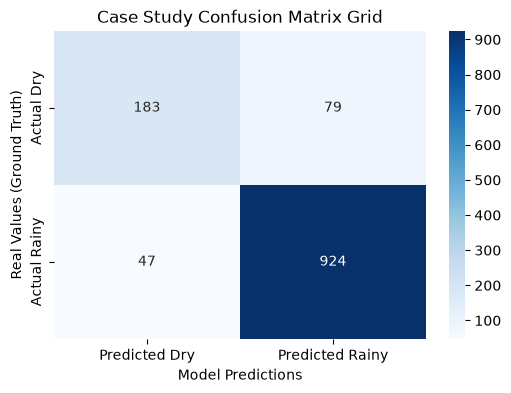

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# We use confusion_matrix() to count the exact number of correct and incorrect predictions
matrix = confusion_matrix(y_test, y_pred)

# We use sns.heatmap() to convert those counts into a clean, color-coded diagnostic grid
plt.figure(figsize=(6, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Predicted Dry", "Predicted Rainy"], 
            yticklabels=["Actual Dry", "Actual Rainy"])

plt.title("Case Study Confusion Matrix Grid")
plt.ylabel("Real Values (Ground Truth)")
plt.xlabel("Model Predictions")
plt.show()
